# Avance 4. Modelos alternativos

**Equipo 51** · Proyecto Integrador, Maestría en Inteligencia Artificial Aplicada (MNA), TC5035
**Proyecto:** AI Co-Pilot Video-to-SOP (patrocinador: Alignity)

## 0. Introducción

**Objetivos del avance**

- **3.3** Construir modelos alternativos al baseline con algoritmos de distintas familias y compararlos con la misma métrica y el mismo protocolo de validación.
- **3.4** Ajustar los hiperparámetros de los modelos más prometedores y elegir el modelo individual final con argumentos de desempeño y de negocio.

**Objetivo del avance.** El avance 3 dejó un baseline (regresión logística) que cumple el desempeño mínimo pero **subajusta ligeramente**: las curvas de aprendizaje convergen cerca de 0.55–0.60 de AUC-PR y más datos ya no ayudan. Este avance prueba si modelos individuales con otra forma de frontera (árboles, vecinos, núcleos, modelos generativos y redes neuronales) extraen más señal de la misma matriz, ajusta los dos mejores y elige un modelo individual final. Los ensambles (bosques, *bagging*, *boosting*, LightGBM, *stacking*) se reservan para el avance 5, que combinará los tres mejores individuales de este avance.

**Vínculo con el producto.** El copiloto marca, para revisión humana, los pasos sospechosos de un video antes de convertirlo en SOP o de validarlo contra uno existente. El modelo correrá **en local y en CPU** (costo cero, ADR-011), y cada marca debe poder explicarse al experto que la revisa. Por eso, además de la métrica, la elección final pesa el tiempo de cómputo, la interpretabilidad, la calidad de las probabilidades (el semáforo las usará como puntaje) y la dependencia de `rec_duration`, una señal del diseño de CaptainCook4D que no se transfiere a planta.

**Preguntas guía y dónde se responden**

| Pregunta | Sección |
|---|---|
| ¿Qué algoritmos individuales son candidatos y por qué? | 4.1 |
| ¿Cuál rinde mejor con la métrica del avance 3? | 4.2 |
| ¿Cuánto depende cada modelo de `rec_duration`? | 4.2 y 6.1 |
| ¿Qué hiperparámetros importan y cuánto mejora el ajuste fino? | 5 |
| ¿Hay sobreajuste al aumentar la capacidad del modelo? | 5.3 y 5.4 |
| ¿Qué modelo individual se elige y por qué? | 6 |
| ¿Qué modelos pasan al *stacking* del avance 5? | 6.4 |

**Particiones.** Las mismas del avance 3: partición oficial de CaptainCook4D por grabación. **Entrenamiento** se usa para ajustar, buscar hiperparámetros, elegir modelos y fijar el umbral, siempre con validación cruzada agrupada (`GroupKFold` por grabación, 5 pliegues). **Validación** solo se usa para la evaluación final de cada modelo: **ninguna decisión de este avance se toma con ella**. **Prueba** no se toca: queda reservada para el modelo final del avance 5.

**Metodología.** CRISP-ML(Q), fase de *Modeling* (Studer et al., 2021): además del desempeño se consideran las medidas "blandas" (explicabilidad, robustez, demanda de recursos y complejidad).

> **Nota de ejecución:** la libreta se corre de principio a fin (*Kernel → Restart & Run All*) en unos 2 minutos en una CPU de 16 hilos; las búsquedas de hiperparámetros usan todos los núcleos (`n_jobs=-1`). Requiere el paquete del proyecto instalado (`pip install -e ".[dev]"` desde la raíz del repositorio) y conexión a internet la primera vez para descargar ~5 MB de anotaciones.

## 1. Configuración del entorno

Las características se importan de `sopvid.features`, sin cambios. Las funciones auxiliares de evaluación son las del avance 3 y se definen en la sección 3.

In [1]:
import re
import time
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    fbeta_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GroupKFold,
    RandomizedSearchCV,
    cross_val_predict,
    cross_val_score,
    validation_curve,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

import sopvid
from sopvid.features import data
from sopvid.features import engineering as fe
from sopvid.features import preprocessing as pp

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = fe.SEED  # 51, igual que en los avances 1 a 3
np.random.seed(SEED)
CV = GroupKFold(n_splits=5)  # pliegues por grabación, como en los avances 2 y 3
N_JOBS = -1                  # búsquedas y curvas en paralelo (no cambia los resultados)
T_START = time.perf_counter()

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
BLUE, RED, GREEN, GRAY = "#2c7fb8", "#c0392b", "#2ca25f", "#7f7f7f"  # paleta del avance 3 + verde validado

print("sopvid", sopvid.__version__, "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

sopvid 0.1.0 | pandas 3.0.6 | numpy 2.4.6 | scipy 1.17.1 | sklearn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Datos: la matriz del avance 3 más `duration`

La conclusión 2 del avance 3 decidió agregar `duration` a las 35 columnas seleccionadas en el avance 2 (+0.017 de AUC-PR, mejor en 5 de 5 pliegues). Se hace con los propios parámetros de `fe.build_features`, sin modificar `sopvid.features`:

1. `build_features(..., select=True)` da las 35 columnas del avance 2.
2. `build_features(..., select=False)` da las 46 construidas, con el pipeline ajustado **solo con entrenamiento**.
3. Todas las transformaciones del pipeline (Yeo-Johnson, `log1p`, `StandardScaler`, codificación por frecuencia y duración relativa) son **columna a columna**, así que tomar de la matriz completa las 35 seleccionadas más `duration` da exactamente la misma matriz que `select=True` más una columna. La celda lo verifica con `assert`.

Se conservan las dos variantes del avance 3: **con `rec_duration`** (36 columnas, referencia académica) y **sin `rec_duration`** (35 columnas, referencia transferible a planta).

In [2]:
raw = data.load_raw()
steps = data.build_step_table(raw.complete, raw.errors_raw)
parts = pp.split_steps(steps, raw.splits)
graphs = data.load_task_graphs(steps["activity_name"].unique())

# Los dos pipelines se ajustan SOLO con entrenamiento y transforman validación.
fs = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info, task_graphs=graphs)
fs_all = fe.build_features(parts["train"], parts["val"], video_info=raw.video_info,
                           task_graphs=graphs, select=False)

# Conclusión 2 del avance 3: las 35 columnas seleccionadas + duration.
COLS = [*fs.X_train.columns, "duration"]
assert np.allclose(fs_all.X_train[fs.X_train.columns], fs.X_train)  # mismas 35 columnas que select=True
assert np.allclose(fs_all.X_test[fs.X_test.columns], fs.X_test)
assert fs_all.y_train.equals(fs.y_train) and fs_all.y_test.equals(fs.y_test)

X_tr, X_va = fs_all.X_train[COLS], fs_all.X_test[COLS]
y_tr, y_va = fs_all.y_train, fs_all.y_test
g_tr = parts["train"].loc[X_tr.index, "recording_id"]  # grupos para GroupKFold

# Variante transferible a planta: sin rec_duration.
Xb_tr, Xb_va = X_tr.drop(columns="rec_duration"), X_va.drop(columns="rec_duration")

PREV_TR, PREV_VA = y_tr.mean(), y_va.mean()
pd.DataFrame({
    "grabaciones": [g_tr.nunique(), parts["val"].loc[X_va.index, "recording_id"].nunique()],
    "pasos ejecutados": [len(X_tr), len(X_va)],
    "columnas (con / sin rec_duration)": [f"{X_tr.shape[1]} / {Xb_tr.shape[1]}", f"{X_va.shape[1]} / {Xb_va.shape[1]}"],
    "% con error": [100 * PREV_TR, 100 * PREV_VA],
    "faltantes": [int(X_tr.isna().sum().sum()), int(X_va.isna().sum().sum())],
}, index=["entrenamiento", "validación"])

,grabaciones,pasos ejecutados,columnas (con / sin rec_duration),% con error,faltantes
entrenamiento,213,2987,36 / 35,24.908,0
validación,62,884,36 / 35,37.783,0


**Observación** Las particiones son las mismas del avance 3: 213 grabaciones y 2,987 pasos ejecutados en entrenamiento, 62 grabaciones y 884 pasos en validación, sin faltantes. La prevalencia sigue siendo distinta (24.9 % contra 37.8 %), así que, como en el avance 3, se reporta el *lift* junto con el AUC-PR. Los `assert` confirman que las 35 columnas tomadas de la matriz completa son idénticas a las de `select=True`: la única diferencia con el avance 3 es la columna `duration`.

## 3. Métrica y protocolo de evaluación

Se conservan sin cambios las decisiones de la sección 3 del avance 3:

| Rol | Métrica | Por qué (resumen del avance 3) |
|---|---|---|
| **Principal** | **AUC-PR** (*average precision*) | Desbalance de 25 %; el modelo **ordena** pasos para revisión humana y el umbral todavía no está fijo. Su valor de azar es la prevalencia. |
| Secundaria | **F2** al umbral de operación | Pesa el recall cuatro veces más que la precisión: dejar pasar un error cuesta más que una revisión de más. |
| Secundaria | **Recall y precisión** | Lo que entiende el experto. |
| Diagnóstico | ROC-AUC, Brier, *lift* (AUC-PR / prevalencia) | Comparabilidad, calidad de las probabilidades y comparación entre particiones con prevalencia distinta (24.9 % contra 37.8 %). |

**Protocolo, idéntico para cada modelo:**

| Paso | Datos | Uso |
|---|---|---|
| AUC-PR por pliegue (`cv_ap`) | entrenamiento, `GroupKFold(5)` | **Única base para comparar, ajustar y elegir.** Se reporta media ± desviación. |
| Probabilidades fuera de pliegue (`oof_proba`) | entrenamiento | Umbral de operación (máximo F2, `f2_threshold`) y Brier de CV. |
| Ajuste completo | entrenamiento | Modelo que se evalúa y tiempo de entrenamiento. |
| Evaluación | validación | Solo reporte, con el umbral elegido en entrenamiento. No se usa para elegir nada. |

**Preprocesamiento.** Como en el avance 3, la matriz sale de `build_features`, cuyo pipeline se ajustó con todo entrenamiento. Sus transformaciones supervisadas o por categoría (duración relativa del paso) se calculan **fuera de pliegue** dentro del propio pipeline; las demás (escalado, Yeo-Johnson) no usan la etiqueta. Ningún modelo de este avance necesita preprocesamiento adicional. La sección 6.2 comprueba con los tres mejores modelos que meter **todo** el preprocesamiento en un `Pipeline` reajustado en cada pliegue no cambia las conclusiones.

In [3]:
def scores(y, p, thr):
    # Métricas de la sección 3: AUC-PR (principal) y las secundarias al umbral de operación.
    yhat = (p >= thr).astype(int)
    return {
        "AUC-PR": average_precision_score(y, p),
        "ROC-AUC": roc_auc_score(y, p),
        "F2": fbeta_score(y, yhat, beta=2, zero_division=0),
        "Recall": recall_score(y, yhat, zero_division=0),
        "Precisión": precision_score(y, yhat, zero_division=0),
        "% marcados": 100 * yhat.mean(),
        "Brier": brier_score_loss(y, p),
    }


def oof_proba(model, X, y, groups=g_tr):
    # Probabilidades fuera de pliegue (cada paso se predice con un modelo que no vio su grabación).
    return cross_val_predict(clone(model), X, y, groups=groups, cv=CV, method="predict_proba")[:, 1]


def cv_ap(model, X, y, groups=g_tr):
    # AUC-PR por pliegue (media y desviación), igual que en los avances 2 y 3.
    out = []
    for tr, te in CV.split(X, y, groups):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        out.append(average_precision_score(y.iloc[te], m.predict_proba(X.iloc[te])[:, 1]))
    return np.array(out)


def f2_threshold(y, p):
    # Umbral que maximiza F2 sobre probabilidades fuera de pliegue de ENTRENAMIENTO.
    prec, rec, thr = precision_recall_curve(y, p)
    f2 = 5 * prec * rec / np.clip(4 * prec + rec, 1e-12, None)
    return float(thr[np.argmax(f2[:-1])])


def evaluate(model, Xtr=None, Xva=None):
    # Protocolo de la sección 3 para un modelo; validación solo se predice al final.
    Xtr = X_tr if Xtr is None else Xtr
    Xva = X_va if Xva is None else Xva
    t0 = time.perf_counter(); fitted = clone(model).fit(Xtr, y_tr); fit_s = time.perf_counter() - t0
    folds = cv_ap(model, Xtr, y_tr)
    p_oof = oof_proba(model, Xtr, y_tr)
    thr = f2_threshold(y_tr, p_oof)
    t0 = time.perf_counter(); p_va = fitted.predict_proba(Xva)[:, 1]; pred_s = time.perf_counter() - t0
    return {"model": fitted, "folds": folds, "p_oof": p_oof, "p_va": p_va, "thr": thr,
            "fit_ms": 1000 * fit_s, "pred_ms_1k": 1000 * pred_s / len(Xva) * 1000,
            "cv": scores(y_tr, p_oof, thr), "val": scores(y_va, p_va, thr)}


def row(r, rb=None):
    # Fila de las tablas comparativas (r: con rec_duration; rb: la misma configuración sin ella).
    out = {"AUC-PR CV": r["folds"].mean(), "desv. CV": r["folds"].std(),
           "AUC-PR val": r["val"]["AUC-PR"], "lift val": r["val"]["AUC-PR"] / PREV_VA,
           "ROC-AUC val": r["val"]["ROC-AUC"], "F2 val": r["val"]["F2"],
           "Recall val": r["val"]["Recall"], "Precisión val": r["val"]["Precisión"],
           "umbral F2": r["thr"], "Brier CV": r["cv"]["Brier"], "entrenamiento (ms)": r["fit_ms"]}
    if rb is not None:
        out["AUC-PR CV sin rec_duration"] = rb["folds"].mean()
        out["AUC-PR val sin rec_duration"] = rb["val"]["AUC-PR"]
    return out

**Referencias sin aprendizaje.** Se recalculan el azar y las reglas de una variable de la sección 4 del avance 3 (sobre la misma matriz), para incluir en la tabla comparativa el azar y la mejor regla simple. También se recalcula el baseline del avance 3 con sus 35 columnas, para separar el efecto de agregar `duration` del efecto de cambiar de algoritmo. Los criterios de desempeño mínimo M1–M3 son los del avance 3.

In [4]:
# Criterios de desempeño mínimo del avance 3 (sección 4), sin cambios.
MIN_LIFT, MIN_RECALL, MIN_PREC_LIFT = 1.5, 0.70, 1.4

rules = {
    "Regla de orden: order_violation = 1": lambda X: X["order_violation"].to_numpy(),
    "Regla de duración: paso más corto que su típico": lambda X: -X["dur_ratio_step"].to_numpy(),
    "Regla de grabación: video más corto": lambda X: -X["rec_duration"].to_numpy(),
}
ref = pd.DataFrame({name: {"AUC-PR train": average_precision_score(y_tr, f(X_tr)),
                           "AUC-PR val": average_precision_score(y_va, f(X_va))}
                    for name, f in rules.items()}).T
BEST_RULE = ref["AUC-PR train"].idxmax()

# Baseline del avance 3 tal cual (35 columnas, C = 1): la referencia a superar.
baseline_a3 = LogisticRegression(class_weight="balanced", max_iter=5000)
res_a3 = evaluate(baseline_a3, fs.X_train, fs.X_test)
print("Mejor regla simple:", BEST_RULE, "| AUC-PR train", f"{ref.loc[BEST_RULE, 'AUC-PR train']:.3f}",
      "| val", f"{ref.loc[BEST_RULE, 'AUC-PR val']:.3f}")
print(f"Baseline del avance 3 (35 col.): AUC-PR CV {res_a3['folds'].mean():.3f} ± {res_a3['folds'].std():.3f}, "
      f"val {res_a3['val']['AUC-PR']:.3f}")

Mejor regla simple: Regla de grabación: video más corto | AUC-PR train 0.401 | val 0.503
Baseline del avance 3 (35 col.): AUC-PR CV 0.551 ± 0.042, val 0.680


## 4. Modelos individuales

### 4.1 Candidatos

El avance 3 concluyó que el baseline subajusta: la relación entre las características y el error no es del todo lineal ni aditiva (por ejemplo, la interacción `duration` × `dur_ratio_step`). Se eligen ocho algoritmos individuales que cubren las familias principales, cada uno con una forma distinta de frontera de decisión. **No se incluyen ensambles** (bosques aleatorios, *bagging*, *boosting*, LightGBM): se reservan para el avance 5.

| Modelo | Familia | Qué puede capturar que la regresión logística no | Desbalance | Configuración inicial y por qué |
|---|---|---|---|---|
| Regresión logística | Lineal discriminativo | (baseline del avance 3) | `class_weight="balanced"` | C = 1, igual que el avance 3. |
| Árbol de decisión | Particiones por umbrales | Interacciones y efectos de umbral, sin suponer linealidad | `class_weight="balanced"` | Profundidad 5 y ≥ 20 pasos por hoja (~0.7 % de entrenamiento), para que no memorice grabaciones. El avance 3 probó profundidad 3. |
| k-NN | Basado en instancias | Fronteras locales arbitrarias: "pasos parecidos a otros pasos con error" | No admite pesos; el AUC-PR no depende de ellos y el umbral F2 compensa | k = √n ≈ 54 (regla práctica), ponderado por distancia. Las columnas ya están estandarizadas, requisito de cualquier método de distancias. |
| SVM con núcleo RBF | Métodos de núcleo | Fronteras no lineales suaves con margen máximo | `class_weight="balanced"` | C = 1, `gamma="scale"` (valores por defecto). Probabilidades con Platt: `CalibratedClassifierCV(method="sigmoid", ensemble=False)`; en scikit-learn 1.9 `probability=True` está obsoleto. Con `ensemble=False` el SVC se ajusta con todo el pliegue y la sigmoide es monótona, así que el orden (y el AUC-PR) es el del SVC. |
| Naive Bayes gaussiano | Generativo | Densidades por clase (supone independencia entre variables) | `priors=[0.5, 0.5]`, el equivalente de balancear | Por defecto. |
| LDA | Generativo lineal | Frontera lineal con covarianza común | `priors=[0.5, 0.5]` | Por defecto (SVD). |
| QDA | Generativo cuadrático | Frontera cuadrática: covarianza propia de cada clase | `priors=[0.5, 0.5]` | `reg_param=0.1`: las 24 columnas *one-hot* de receta hacen singular la covarianza de cada clase. |
| MLP | Red neuronal | Interacciones aprendidas por capas ocultas | No admite `class_weight`; mismo argumento que k-NN | Por defecto (100 neuronas ReLU, Adam, `alpha=1e-4`) con `early_stopping=True` (10 % interno) para detener el entrenamiento cuando deja de mejorar. |

Cada modelo se evalúa con y sin `rec_duration`, con la misma configuración.

In [5]:
EQUAL = [0.5, 0.5]  # priors iguales: equivalente a class_weight="balanced" en los modelos generativos
models = {
    "Regresión logística": LogisticRegression(class_weight="balanced", max_iter=5000),
    "Árbol de decisión": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, class_weight="balanced",
                                                random_state=SEED),
    "k-NN": KNeighborsClassifier(n_neighbors=int(np.sqrt(len(X_tr))), weights="distance"),
    "SVM (RBF)": CalibratedClassifierCV(SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced",
                                            random_state=SEED), method="sigmoid", cv=3, ensemble=False),
    "Naive Bayes gaussiano": GaussianNB(priors=EQUAL),
    "LDA": LinearDiscriminantAnalysis(priors=EQUAL),
    "QDA": QuadraticDiscriminantAnalysis(priors=EQUAL, reg_param=0.1),
    "MLP": MLPClassifier(early_stopping=True, max_iter=1000, random_state=SEED),
}

t0 = time.perf_counter()
res, res_b = {}, {}  # con y sin rec_duration
for name, m in models.items():
    res[name] = evaluate(m)
    res_b[name] = evaluate(m, Xb_tr, Xb_va)
print(f"8 modelos × 2 variantes evaluados en {time.perf_counter() - t0:.0f} s")

8 modelos × 2 variantes evaluados en 25 s


### 4.2 Tabla comparativa

Ordenada por AUC-PR CV (media de los 5 pliegues). F2, recall y precisión se miden en validación con el umbral elegido en entrenamiento; el Brier es el de las probabilidades fuera de pliegue. Las filas de referencia (azar, mejor regla simple y baseline del avance 3 con 35 columnas) se marcan con "ref.".

In [6]:
comp = pd.DataFrame({name: row(res[name], res_b[name]) for name in models}).T
comp.insert(0, "tipo", "individual")
refs = pd.DataFrame({
    "Azar (prevalencia)": {"AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA, "lift val": 1.0,
                           "AUC-PR CV sin rec_duration": PREV_TR, "AUC-PR val sin rec_duration": PREV_VA},
    BEST_RULE: {"AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"], "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"],
                "lift val": ref.loc[BEST_RULE, "AUC-PR val"] / PREV_VA},
    "Baseline del avance 3 (35 col.)": row(res_a3),
}).T
refs.insert(0, "tipo", "ref.")
table = pd.concat([comp, refs]).sort_values("AUC-PR CV", ascending=False)
table

,tipo,AUC-PR CV,desv. CV,AUC-PR val,lift val,ROC-AUC val,F2 val,Recall val,Precisión val,umbral F2,Brier CV,entrenamiento (ms),AUC-PR CV sin rec_duration,AUC-PR val sin rec_duration
SVM (RBF),individual,0.589,0.051,0.707,1.870,0.819,0.790,0.880,0.561,0.192,0.162,870.716,0.505,0.660
MLP,individual,0.568,0.054,0.736,1.948,0.800,0.786,0.922,0.494,0.123,0.152,283.359,0.496,0.643
Regresión logística,individual,0.568,0.045,0.690,1.827,0.807,0.787,0.883,0.547,0.296,0.190,20.632,0.481,0.638
Baseline del avance 3 (35 col.),ref.,0.551,0.042,0.680,1.799,0.802,0.777,0.871,0.542,0.308,0.192,19.031,NaN,NaN
LDA,individual,0.551,0.049,0.703,1.860,0.810,0.753,0.823,0.560,0.315,0.189,8.833,0.481,0.649
k-NN,individual,0.524,0.054,0.706,1.870,0.781,0.780,0.958,0.448,0.109,0.161,1.818,0.467,0.665
QDA,individual,0.478,0.059,0.642,1.700,0.765,0.756,0.853,0.518,0.057,0.190,8.428,0.432,0.600
Regla de grabación: video más corto,ref.,0.401,NaN,0.503,1.332,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Naive Bayes gaussiano,individual,0.391,0.031,0.615,1.628,0.688,0.725,0.904,0.404,0.000,0.357,4.140,0.384,0.599
Árbol de decisión,individual,0.373,0.066,0.570,1.510,0.708,0.773,0.970,0.426,0.016,0.249,7.104,0.383,0.588


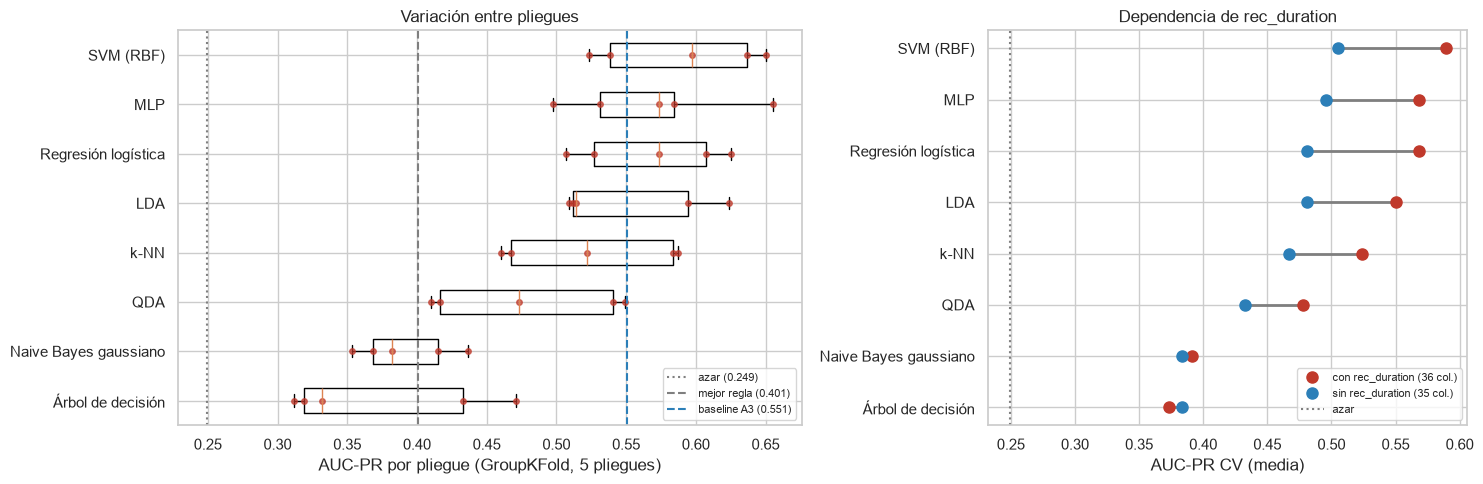

In [7]:
order = comp.sort_values("AUC-PR CV").index
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})

# 1) AUC-PR por pliegue: ¿las diferencias son mayores que la variación entre pliegues?
axes[0].boxplot([res[n]["folds"] for n in order], orientation="horizontal", tick_labels=order,
                showfliers=False, widths=0.5)
for i, n in enumerate(order, start=1):
    axes[0].plot(res[n]["folds"], np.full(5, i), "o", color=RED, ms=4, alpha=0.7)
axes[0].axvline(PREV_TR, color=GRAY, ls=":", label=f"azar ({PREV_TR:.3f})")
axes[0].axvline(ref.loc[BEST_RULE, "AUC-PR train"], color=GRAY, ls="--",
                label=f"mejor regla ({ref.loc[BEST_RULE, 'AUC-PR train']:.3f})")
axes[0].axvline(res_a3["folds"].mean(), color=BLUE, ls="--", label=f"baseline A3 ({res_a3['folds'].mean():.3f})")
axes[0].set_xlabel("AUC-PR por pliegue (GroupKFold, 5 pliegues)")
axes[0].set_title("Variación entre pliegues"); axes[0].legend(fontsize=8, loc="lower right")

# 2) Con y sin rec_duration (misma configuración)
y_pos = np.arange(len(order))
with_rd = comp.loc[order, "AUC-PR CV"]; without_rd = comp.loc[order, "AUC-PR CV sin rec_duration"]
axes[1].hlines(y_pos, without_rd, with_rd, color=GRAY, lw=2)
axes[1].plot(with_rd, y_pos, "o", color=RED, ms=8, label="con rec_duration (36 col.)")
axes[1].plot(without_rd, y_pos, "o", color=BLUE, ms=8, label="sin rec_duration (35 col.)")
axes[1].set_yticks(y_pos, order)
axes[1].axvline(PREV_TR, color=GRAY, ls=":", label="azar")
axes[1].set_xlabel("AUC-PR CV (media)"); axes[1].set_title("Dependencia de rec_duration")
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Interpretación**

- **Tres grupos.** (1) Los modelos de frontera suave quedan arriba y juntos: SVM (0.589), MLP y regresión logística (0.568) y LDA (0.551). La distancia entre ellos es menor que la desviación entre pliegues (0.045–0.054). (2) k-NN (0.524) y QDA (0.478) quedan en medio. (3) Naive Bayes (0.391) y el árbol (0.373) **no superan la mejor regla simple** (0.401) en CV, así que no cumplen M2.
- **Por qué fallan el árbol y Naive Bayes.** El árbol de profundidad 5 da pocas probabilidades distintas (una por hoja) y es el más inestable entre pliegues (desv. 0.066). Naive Bayes supone independencia entre variables que están correlacionadas (las de grabación y las de posición), lo que vuelve extremas sus probabilidades (Brier 0.357 y umbral F2 ≈ 0): ordena peor y además está mal calibrado.
- **`duration` confirma la decisión del avance 3.** La misma regresión logística pasa de 0.551 (35 columnas) a 0.568 (36 columnas) en CV y de 0.680 a 0.690 en validación.
- **Segundo lugar empatado.** El MLP (0.56828) supera a la regresión logística (0.56800) por 0.0003, una diferencia muy por debajo de la variación entre pliegues. La regla de 5.1 se aplica tal cual y el MLP pasa al ajuste fino. Se pierde poco por no ajustar la regresión logística: el avance 3 ya mostró (sección 7.3) que su AUC-PR es plano para C ≥ 0.3.
- **Validación.** Los cuatro mejores quedan entre 0.69 y 0.74 (lift 1.83–1.95). k-NN rinde bien en validación (0.706) pese a quedar quinto en CV, un recordatorio de que 62 grabaciones de validación tienen su propio ruido y de por qué la elección se hace con CV.
- **`rec_duration`.** Todos los modelos que la usan pierden entre 0.05 y 0.09 de AUC-PR sin ella. El árbol y Naive Bayes casi no cambian porque apenas la aprovechan. El orden se mantiene (SVM 0.505, MLP 0.496, regresión logística 0.481), y los cuatro mejores siguen por encima de M1 (0.374) sin ella.
- **Tiempo.** Todos entrenan en menos de un segundo en CPU. La SVM es la más lenta (~0.8 s) porque la calibración de Platt la ajusta cuatro veces (3 pliegues internos y el ajuste final).

## 5. Ajuste fino de los dos mejores

### 5.1 Selección y espacios de búsqueda

Se ajustan los **dos mejores por AUC-PR CV** de la tabla 4.2 (la regla se aplica en código, sin mirar validación). Cada búsqueda usa `RandomizedSearchCV` con `scoring="average_precision"`, la misma `GroupKFold(5)` con sus grupos, 60 configuraciones y `random_state=SEED`. La búsqueda aleatoria explora mejor que una malla cuando solo unos pocos hiperparámetros importan (Bergstra y Bengio, 2012), y con 60 configuraciones la probabilidad de caer en el 5 % superior del espacio es 1 − 0.95⁶⁰ ≈ 95 %.

Los espacios se definen para los ocho modelos (así la regla no depende de cuáles resulten ganadores) y son **amplios**: cubren varios órdenes de magnitud en escala logarítmica para los hiperparámetros de regularización.

| Modelo | Hiperparámetro | Espacio | Por qué |
|---|---|---|---|
| Regresión logística | `C` | log-uniforme 10⁻⁴–10² | Regularización, de muy fuerte a casi nula (la meseta del avance 3 empezaba en 0.3). |
| | `l1_ratio` | uniforme 0–1 (`saga`) | Red elástica: de L2 pura a L1 pura; L1 descartó ~6 columnas en el avance 3. |
| Árbol de decisión | `max_depth` | 2–20 y sin límite | Capacidad: de un tocón a un árbol completo. |
| | `min_samples_leaf` | 1–200 | Suavizado: hojas grandes evitan memorizar grabaciones. |
| | `ccp_alpha` | log-uniforme 10⁻⁵–10⁻¹ | Poda por costo-complejidad. |
| | `criterion`, `max_features` | gini/entropía; todas, √p o 50 % | Criterio de corte y aleatorización de columnas. |
| k-NN | `n_neighbors` | 5–300 | Del vecindario local a casi un promedio global. |
| | `weights`, `p` | uniforme/distancia; Manhattan/Euclidiana | Peso de los vecinos y métrica. |
| SVM | `C` | log-uniforme 10⁻²–10² | Ancho del margen (regularización). |
| | `gamma` | log-uniforme 10⁻⁴–1 | Alcance del núcleo: de casi lineal a muy local (`"scale"` ≈ 1/36 ≈ 0.03 está en el centro). |
| | `kernel`, `degree` | RBF, polinomial (grado 2 o 3), sigmoide | Forma de la frontera. |
| Naive Bayes | `var_smoothing` | log-uniforme 10⁻¹²–1 | Varianza añadida para estabilizar las densidades. |
| LDA | `shrinkage` | uniforme 0–1 (`lsqr`) | Contracción de la covarianza hacia la diagonal. |
| QDA | `reg_param` | uniforme 0–1 | Regularización de cada covarianza. |
| MLP | `hidden_layer_sizes` | 1 o 2 capas, 16–128 neuronas | Capacidad. Más capas no se justifican con 213 grabaciones. |
| | `alpha` | log-uniforme 10⁻⁵–10 | Penalización L2: el control principal del sobreajuste. |
| | `learning_rate_init` | log-uniforme 10⁻⁴–10⁻¹ | Paso de Adam. |
| | `activation` | ReLU, tanh, logística | No linealidad. |

In [8]:
N_ITER = 60
SPACES = {
    "Regresión logística": {"solver": ["saga"], "max_iter": [20000],
                            "C": loguniform(1e-4, 1e2), "l1_ratio": uniform(0, 1)},
    "Árbol de decisión": {"max_depth": [*range(2, 21), None], "min_samples_leaf": randint(1, 201),
                          "ccp_alpha": loguniform(1e-5, 1e-1), "criterion": ["gini", "entropy"],
                          "max_features": [None, "sqrt", 0.5]},
    "k-NN": {"n_neighbors": randint(5, 301), "weights": ["uniform", "distance"], "p": [1, 2]},
    "SVM (RBF)": {"estimator__C": loguniform(1e-2, 1e2), "estimator__gamma": loguniform(1e-4, 1e0),
                  "estimator__kernel": ["rbf", "poly", "sigmoid"], "estimator__degree": [2, 3]},
    "Naive Bayes gaussiano": {"var_smoothing": loguniform(1e-12, 1e0)},
    "LDA": {"solver": ["lsqr"], "shrinkage": uniform(0, 1)},
    "QDA": {"reg_param": uniform(0, 1)},
    "MLP": {"hidden_layer_sizes": [(16,), (32,), (64,), (128,), (32, 16), (64, 32), (128, 64)],
            "alpha": loguniform(1e-5, 1e1), "learning_rate_init": loguniform(1e-4, 1e-1),
            "activation": ["relu", "tanh", "logistic"]},
}
FIXED = {"solver", "max_iter"}  # valores fijos dentro del espacio, no son hiperparámetros a explorar

TOP2 = list(comp.sort_values("AUC-PR CV", ascending=False).index[:2])
print("Se ajustan:", TOP2)

Se ajustan: ['SVM (RBF)', 'MLP']


### 5.2 Búsqueda aleatoria

In [9]:
searches, search_s = {}, {}
for name in TOP2:
    t0 = time.perf_counter()
    rs = RandomizedSearchCV(clone(models[name]), SPACES[name], n_iter=N_ITER, scoring="average_precision",
                            cv=CV, random_state=SEED, n_jobs=N_JOBS, return_train_score=True)
    rs.fit(X_tr, y_tr, groups=g_tr)
    searches[name], search_s[name] = rs, time.perf_counter() - t0
    print(f"{name}: {N_ITER} configuraciones × 5 pliegues en {search_s[name]:.0f} s | "
          f"mejor AUC-PR CV {rs.best_score_:.3f}")

tuned = {n: clone(models[n]).set_params(**searches[n].best_params_) for n in TOP2}
res_t = {n: evaluate(m) for n, m in tuned.items()}
res_tb = {n: evaluate(m, Xb_tr, Xb_va) for n, m in tuned.items()}
for n in TOP2:  # la búsqueda y cv_ap usan los mismos pliegues: deben coincidir
    assert np.isclose(res_t[n]["folds"].mean(), searches[n].best_score_)

pd.DataFrame({n: {k.replace("estimator__", ""): v for k, v in searches[n].best_params_.items() if k not in FIXED}
              for n in TOP2}).T

SVM (RBF): 60 configuraciones × 5 pliegues en 37 s | mejor AUC-PR CV 0.599


MLP: 60 configuraciones × 5 pliegues en 11 s | mejor AUC-PR CV 0.602


,C,degree,gamma,kernel,activation,alpha,hidden_layer_sizes,learning_rate_init
SVM (RBF),32.829,3,0.016,rbf,NaN,NaN,NaN,NaN
MLP,NaN,NaN,NaN,NaN,relu,0.258,"(32, 16)",0.010


**Antes y después.** "Pliegues mejores" cuenta en cuántos de los 5 pliegues la configuración ajustada supera a la inicial; como en el avance 3, una mejora en 5 de 5 pliegues no es ruido aunque sea menor que la desviación. El AUC-PR CV del mejor de 60 configuraciones es algo optimista (se eligió con esos mismos pliegues); validación, que no participó en la búsqueda, es la comprobación independiente.

In [10]:
ba = []
for n in TOP2:
    b, a = res[n], res_t[n]
    ba.append({"modelo": n,
               "AUC-PR CV antes": b["folds"].mean(), "AUC-PR CV después": a["folds"].mean(),
               "Δ CV": a["folds"].mean() - b["folds"].mean(),
               "desv. CV después": a["folds"].std(),
               "pliegues mejores": int((a["folds"] > b["folds"] + 1e-9).sum()),
               "AUC-PR val antes": b["val"]["AUC-PR"], "AUC-PR val después": a["val"]["AUC-PR"],
               "Δ val": a["val"]["AUC-PR"] - b["val"]["AUC-PR"],
               "F2 val antes": b["val"]["F2"], "F2 val después": a["val"]["F2"],
               "Brier CV antes": b["cv"]["Brier"], "Brier CV después": a["cv"]["Brier"],
               "sin rec_duration CV antes": res_b[n]["folds"].mean(),
               "sin rec_duration CV después": res_tb[n]["folds"].mean(),
               "búsqueda (s)": search_s[n]})
before_after = pd.DataFrame(ba).set_index("modelo")
before_after.T

modelo,SVM (RBF),MLP
AUC-PR CV antes,0.589,0.568
AUC-PR CV después,0.599,0.602
Δ CV,0.010,0.034
desv. CV después,0.024,0.041
pliegues mejores,3.000,4.000
AUC-PR val antes,0.707,0.736
AUC-PR val después,0.686,0.731
Δ val,-0.020,-0.005
F2 val antes,0.790,0.786
F2 val después,0.750,0.818


**Interpretación**

- **SVM.** La búsqueda movió la configuración hacia más C (≈ 33, menos regularización) y un núcleo algo más ancho (gamma ≈ 0.016, frente a `"scale"` ≈ 0.028). El AUC-PR CV sube +0.010 (3 de 5 pliegues) y la desviación entre pliegues baja de 0.051 a 0.024, pero **validación no confirma la mejora** (0.707 → 0.686). La configuración inicial ya estaba cerca del óptimo; el ajuste encontró una zona equivalente con un resultado más estable entre pliegues. Lo que sí mejora con claridad es la variante **sin `rec_duration`** (+0.044 en CV, de 0.505 a 0.549): la configuración ajustada se apoya menos en la duración del video.
- **MLP.** La mejor configuración tiene dos capas (32, 16), `alpha` ≈ 0.26 (unas 2,600 veces el valor por defecto, una regularización fuerte) y una tasa de aprendizaje de 0.01. Sube +0.034 en CV (4 de 5 pliegues) y +0.037 sin `rec_duration`; en validación queda igual (0.736 → 0.731) y el F2 mejora (+0.03). La sección 6.1 muestra que parte de esa ganancia es suerte de la semilla.
- **Optimismo de la búsqueda.** El mejor de 60 se eligió con los mismos pliegues que lo evalúan, así que su AUC-PR CV está inflado. En los dos modelos, validación muestra que la ganancia real del ajuste fino es pequeña: lo que separa a estos modelos del baseline es su forma de frontera, no el ajuste fino.
- **Costo.** 35 s (SVM) y 12 s (MLP) con 16 hilos, muy por debajo del límite de ~10 min, así que no hizo falta reducir la búsqueda.

### 5.3 Distribución de los resultados de la búsqueda

Para cada modelo: el histograma del AUC-PR CV de las 60 configuraciones (con la configuración inicial y la mejor), la brecha entre entrenamiento y CV de cada configuración (señal de sobreajuste) y el AUC-PR CV contra cada hiperparámetro.

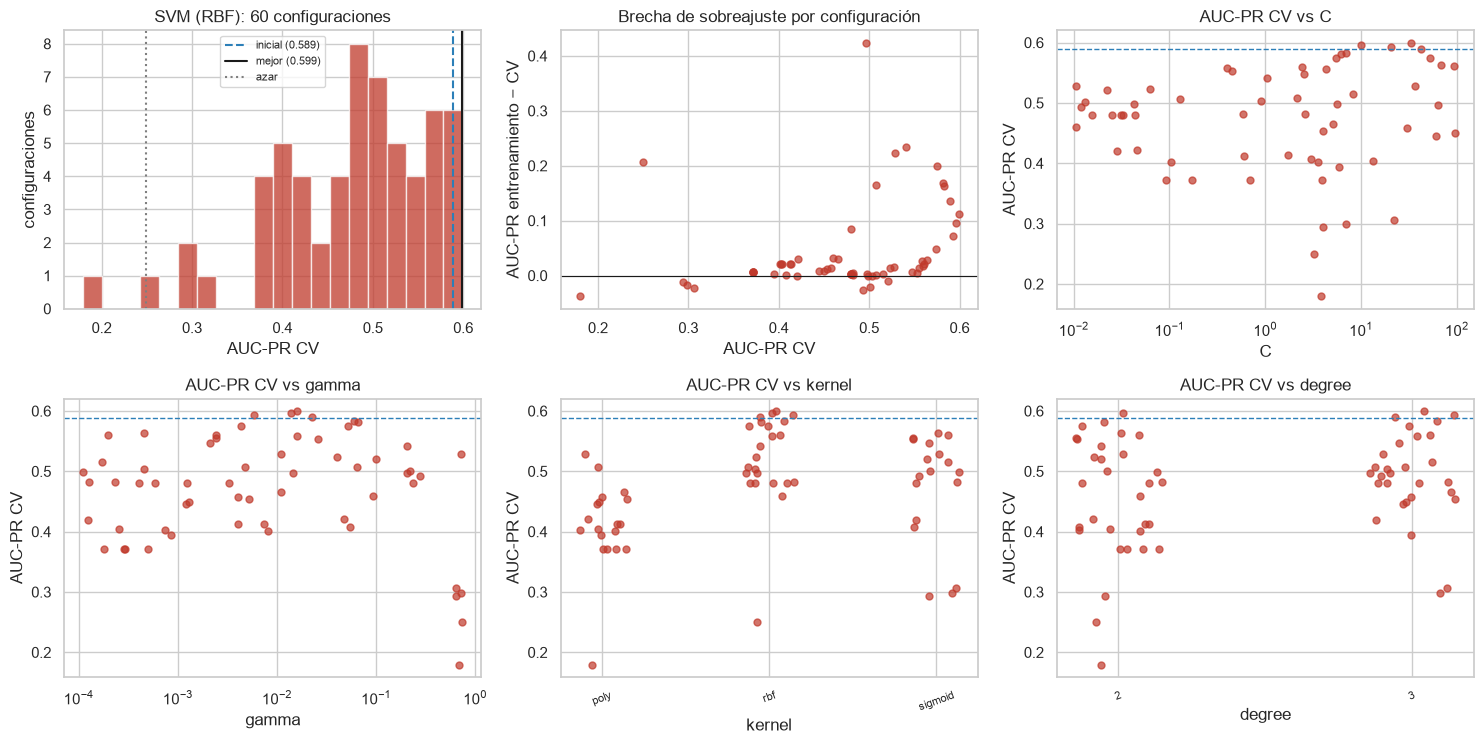

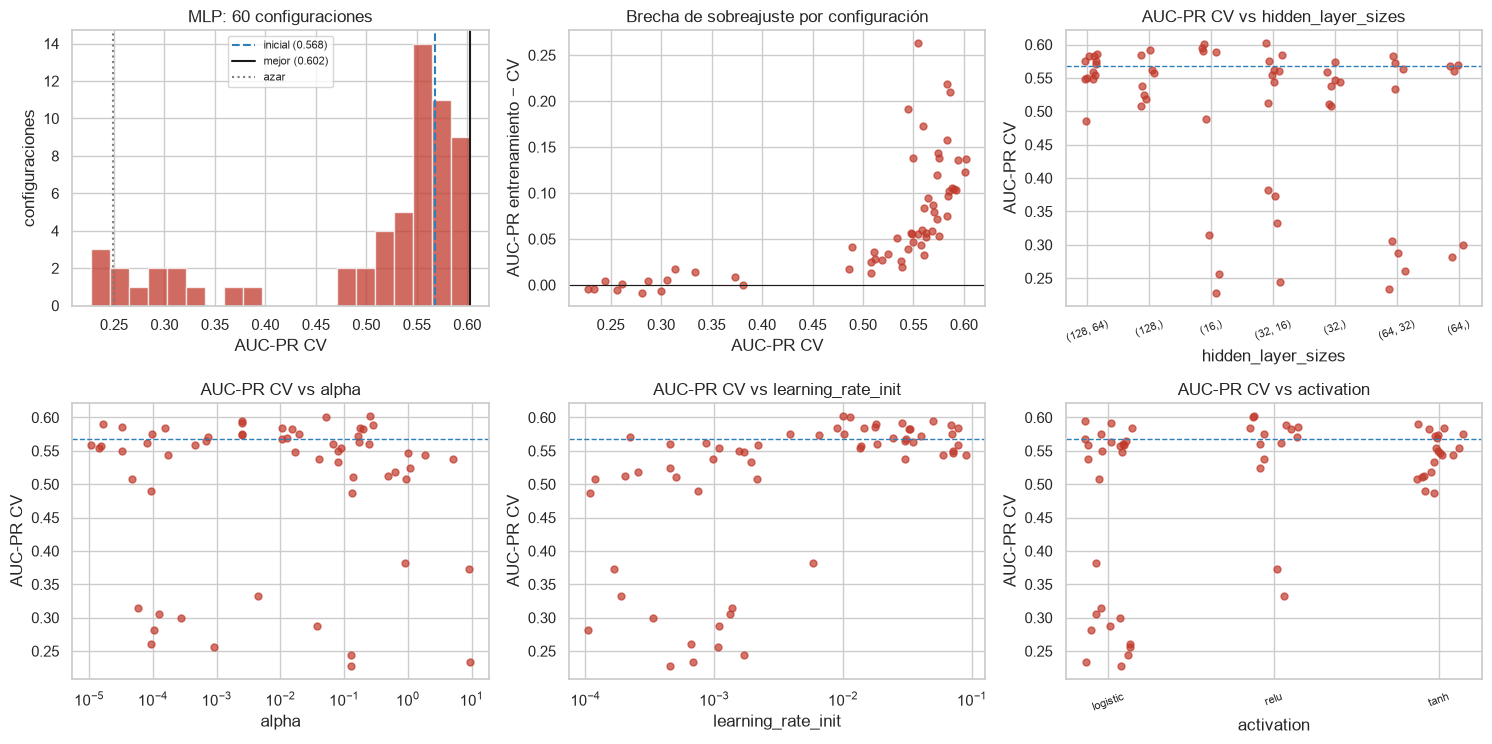

In [11]:
def is_numeric_param(v):
    num = pd.to_numeric(pd.Series(v), errors="coerce")
    return num.notna().all() and num.nunique() > 5


for n in TOP2:
    r = pd.DataFrame(searches[n].cv_results_)
    params = [p for p in SPACES[n] if p not in FIXED]
    ncols = 3
    nrows = int(np.ceil((2 + len(params)) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.8 * nrows))
    axes = axes.ravel()

    axes[0].hist(r["mean_test_score"], bins=20, color=RED, alpha=0.75, edgecolor="white")
    axes[0].axvline(res[n]["folds"].mean(), color=BLUE, ls="--", label=f"inicial ({res[n]['folds'].mean():.3f})")
    axes[0].axvline(searches[n].best_score_, color="k", ls="-", label=f"mejor ({searches[n].best_score_:.3f})")
    axes[0].axvline(PREV_TR, color=GRAY, ls=":", label="azar")
    axes[0].set_xlabel("AUC-PR CV"); axes[0].set_ylabel("configuraciones")
    axes[0].set_title(f"{n}: {N_ITER} configuraciones"); axes[0].legend(fontsize=8)

    gap = r["mean_train_score"] - r["mean_test_score"]
    axes[1].scatter(r["mean_test_score"], gap, color=RED, alpha=0.7, s=25)
    axes[1].axhline(0, color="k", lw=0.8)
    axes[1].set_xlabel("AUC-PR CV"); axes[1].set_ylabel("AUC-PR entrenamiento − CV")
    axes[1].set_title("Brecha de sobreajuste por configuración")

    for ax, p in zip(axes[2:], params):
        v = r[f"param_{p}"]
        label = p.replace("estimator__", "")
        if is_numeric_param(v):
            x = pd.to_numeric(v)
            ax.scatter(x, r["mean_test_score"], color=RED, alpha=0.7, s=25)
            if x.max() / max(x.min(), 1e-12) > 50:
                ax.set_xscale("log")
        else:
            cats = v.astype(str)
            levels = sorted(cats.unique())
            pos = cats.map({c: i for i, c in enumerate(levels)})
            jitter = np.random.default_rng(SEED).uniform(-0.15, 0.15, len(pos))
            ax.scatter(pos + jitter, r["mean_test_score"], color=RED, alpha=0.7, s=25)
            ax.set_xticks(range(len(levels)), levels, rotation=20, fontsize=8)
        ax.axhline(res[n]["folds"].mean(), color=BLUE, ls="--", lw=1)
        ax.set_xlabel(label); ax.set_ylabel("AUC-PR CV"); ax.set_title(f"AUC-PR CV vs {label}")
    for ax in axes[2 + len(params):]:
        ax.set_visible(False)
    plt.tight_layout(); plt.show()

**Interpretación**

- **SVM.** La mayoría de las 60 configuraciones queda entre 0.40 y 0.60, y solo unas seis llegan a ~0.59–0.60: la configuración inicial ya estaba en el 10 % superior. Por núcleo, el **polinomial** es el peor (casi todas sus configuraciones por debajo de 0.53), el sigmoide queda en medio y el **RBF** concentra las mejores. Con `gamma` cercano a 1 el desempeño se desploma (≤ 0.31) en cualquier núcleo. Las mejores configuraciones combinan C alto (10–100) con gamma moderado.
- **MLP.** La distribución es bimodal: la mayoría queda entre 0.50 y 0.60, más un grupo de fallos cerca del azar (0.22–0.40). Los fallos son configuraciones con tasa de aprendizaje baja (< 2·10⁻³), sobre todo con activación logística: `early_stopping` detiene el entrenamiento antes de que la red aprenda. El tamaño de las capas casi no importa una vez que el entrenamiento converge.
- **Brecha de sobreajuste.** En los dos modelos la brecha entre entrenamiento y CV **crece con el AUC-PR CV**: las configuraciones que más rinden son también las que más se ajustan a entrenamiento (0.07–0.17 en la SVM y 0.05–0.25 en el MLP), frente a ~0.05 del baseline en el avance 3. El ajuste fino aprovecha capacidad que la regresión logística no tenía, pero las mejores configuraciones ya están en el límite del sobreajuste.

### 5.4 Hiperparámetro más influyente y curva de validación

La influencia de cada hiperparámetro se mide sobre las 60 configuraciones: se agrupan por su valor (en 5 quintiles si es numérico, por categoría si no) y se toma la diferencia entre el mejor y el peor promedio de AUC-PR CV. Con el más influyente **numérico** se traza una curva de validación (los demás hiperparámetros fijos en su mejor valor), que muestra entrenamiento y CV y, por lo tanto, en qué zona el modelo sub o sobreajusta. Si un categórico resulta más influyente, su efecto ya se ve en los paneles de 5.3.

numérico  rango de AUC-PR CV entre grupos        mejor grupo
modelo    hiperparámetro                                                                  
SVM (RBF) gamma                   True                            0.123   (0.0151, 0.0949]
          kernel                 False                            0.110                rbf
          C                       True                            0.087   (14.726, 95.546]
          degree                 False                            0.038                  3
MLP       learning_rate_init      True                            0.166   (0.0122, 0.0324]
          hidden_layer_sizes     False                            0.142          (128, 64)
          activation             False                            0.102               tanh
          alpha                   True                            0.050  (0.00254, 0.0714]

SVM (RBF) · gamma:
 valor  train    CV
 0.000  0.559 0.550
 0.000  0.586 0.563
 0.001  0.610 0.573
 0.003  0.647 0.585
 0.010  0.695 0.599
 0.032  0.738 0.585
 0.100  0.810 0.549
 0.316  0.945 0.467
 1.000  0.137 0.187


MLP · learning_rate_init:
 valor  train    CV
 0.000  0.353 0.340
 0.000  0.529 0.503
 0.001  0.581 0.529
 0.003  0.695 0.578
 0.010  0.744 0.602
 0.032  0.712 0.594
 0.100  0.670 0.583


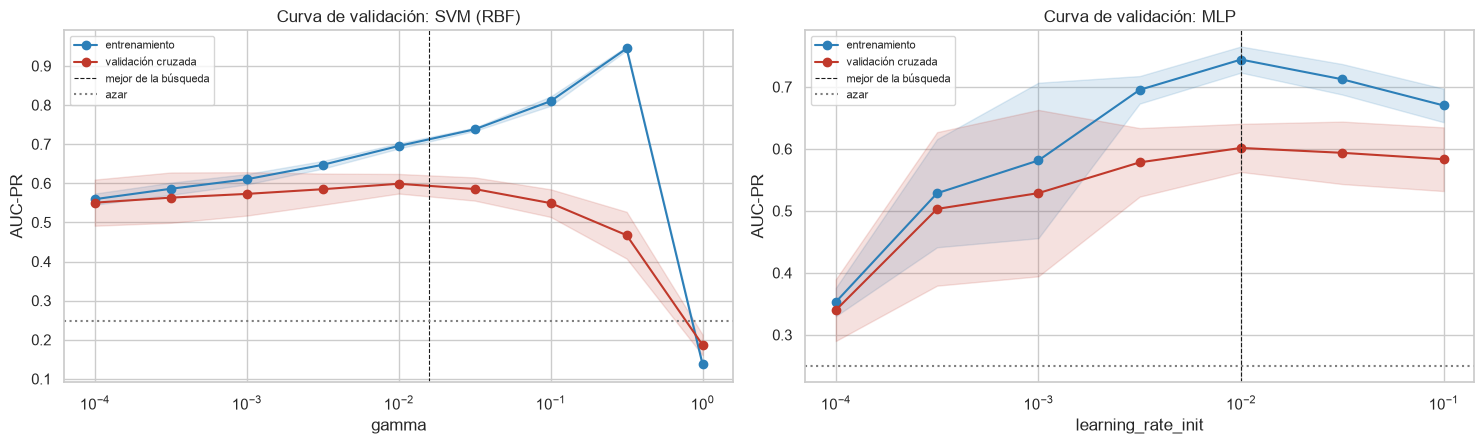

In [12]:
VC_GRID = {
    "C": np.logspace(-4, 2, 13), "l1_ratio": np.linspace(0, 1, 6),
    "max_depth": [2, 3, 4, 5, 6, 8, 10, 15, 20], "min_samples_leaf": [1, 5, 10, 20, 50, 100, 150, 200],
    "ccp_alpha": np.logspace(-5, -1, 9), "n_neighbors": [5, 10, 25, 50, 100, 150, 200, 300],
    "estimator__C": np.logspace(-2, 2, 9), "estimator__gamma": np.logspace(-4, 0, 9),
    "var_smoothing": np.logspace(-12, 0, 7), "shrinkage": np.linspace(0, 1, 11),
    "reg_param": np.linspace(0, 1, 11), "alpha": np.logspace(-5, 1, 13),
    "learning_rate_init": np.logspace(-4, -1, 7),
}


def influence(name):
    r = pd.DataFrame(searches[name].cv_results_)
    out = []
    for p in SPACES[name]:
        if p in FIXED:
            continue
        v = r[f"param_{p}"]
        numeric = is_numeric_param(v)
        key = pd.qcut(pd.to_numeric(v), 5, duplicates="drop") if numeric else v.astype(str)
        means = r.groupby(key, observed=True)["mean_test_score"].mean()
        out.append({"modelo": name, "hiperparámetro": p.replace("estimator__", ""), "_param": p,
                    "numérico": numeric, "rango de AUC-PR CV entre grupos": means.max() - means.min(),
                    "mejor grupo": str(means.idxmax())})
    return pd.DataFrame(out).sort_values("rango de AUC-PR CV entre grupos", ascending=False)


infl = pd.concat([influence(n) for n in TOP2])
display(infl.drop(columns="_param").set_index(["modelo", "hiperparámetro"]))

fig, axes = plt.subplots(1, len(TOP2), figsize=(7.5 * len(TOP2), 4.6))
vc_param = {}
for ax, n in zip(np.atleast_1d(axes), TOP2):
    p = infl[(infl["modelo"] == n) & infl["numérico"]].iloc[0]["_param"]
    vc_param[n] = p
    grid = VC_GRID[p]
    v_tr, v_te = validation_curve(clone(tuned[n]), X_tr, y_tr, groups=g_tr, cv=CV, param_name=p,
                                  param_range=grid, scoring="average_precision", n_jobs=N_JOBS)
    for sc, lab, col in [(v_tr, "entrenamiento", BLUE), (v_te, "validación cruzada", RED)]:
        ax.plot(grid, sc.mean(1), "o-", color=col, label=lab)
        ax.fill_between(grid, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=col, alpha=0.15)
    ax.axvline(searches[n].best_params_[p], color="k", ls="--", lw=0.8, label="mejor de la búsqueda")
    ax.axhline(PREV_TR, color=GRAY, ls=":", label="azar")
    ax.set_xscale("log" if np.max(grid) / max(np.min(grid), 1e-12) > 50 else "linear")
    ax.set_xlabel(p.replace("estimator__", "")); ax.set_ylabel("AUC-PR")
    ax.set_title(f"Curva de validación: {n}"); ax.legend(fontsize=8)
    print(f"{n} · {p.replace('estimator__', '')}:",
          pd.DataFrame({"valor": grid, "train": v_tr.mean(1), "CV": v_te.mean(1)}).round(3).to_string(index=False),
          sep="\n")
plt.tight_layout(); plt.show()

**Interpretación**

- **SVM: `gamma` es el hiperparámetro más influyente** (rango de 0.123 entre quintiles, por encima del núcleo y de C). La curva muestra el compromiso entre sesgo y varianza. Con gamma = 10⁻⁴ el núcleo es casi lineal: entrenamiento y CV coinciden (0.56 y 0.55), al nivel de la regresión logística (**subajuste**). Al subir gamma, entrenamiento crece sin parar (0.95 en gamma ≈ 0.3), mientras que CV llega a su máximo en gamma ≈ 0.01 (0.599) y después cae (0.47 en gamma ≈ 0.3): **sobreajuste**, el núcleo se vuelve tan local que memoriza grabaciones. En gamma = 1 colapsan las dos curvas, probablemente porque la sigmoide de Platt se ajusta con predicciones internas sin información y deja de ordenar incluso los datos de entrenamiento. El valor elegido (0.016) está en la cima de CV, con una brecha de ~0.10.
- **MLP: `learning_rate_init` es el más influyente** (0.166). Con 10⁻⁴ entrenamiento y CV quedan juntos y bajos (0.35 y 0.34): `early_stopping` corta antes de aprender (**subajuste por optimización**, no por capacidad). El máximo de CV está en 0.01 (0.602), con una brecha de 0.14. Con tasas mayores bajan las dos curvas, por inestabilidad de Adam. La banda de ±1 desviación es ancha en tasas bajas: ahí el resultado depende mucho del pliegue.

## 6. Modelo individual final

### 6.1 Los tres mejores con criterios más allá de la métrica

Se reordenan los ocho modelos con las configuraciones ajustadas de 5.2 y se comparan los tres primeros con los criterios de CRISP-ML(Q) que importan para el producto:

| Criterio | Cómo se mide | Por qué importa |
|---|---|---|
| Diferencia contra la varianza | Diferencia por pliegue frente al mejor: media, desviación y pliegues en que lo iguala o supera | Una ventaja menor que la variación entre pliegues no justifica un modelo más complejo. |
| Interpretabilidad | Cualitativa | El experto que revisa una marca debe entender por qué se marcó. |
| Tiempo en CPU | Entrenamiento y predicción por cada 1,000 pasos | Producto local y de costo cero (ADR-011). |
| Calibración | Brier fuera de pliegue y en validación (menor es mejor) | El semáforo usará la probabilidad como puntaje. |
| Dependencia de `rec_duration` | AUC-PR sin ella, con la misma configuración | La duración del video no se transfiere a planta. |

In [13]:
INTERPRETABILITY = {
    "Regresión logística": "alta: coeficientes y razones de momios",
    "LDA": "alta: coeficientes lineales",
    "Árbol de decisión": "alta si es poco profundo: reglas legibles",
    "Naive Bayes gaussiano": "media: aporte de cada variable a la verosimilitud",
    "k-NN": "media: se explica con los pasos vecinos",
    "QDA": "baja: frontera cuadrática con 36 dimensiones",
    "SVM (RBF)": "baja: solo métodos agnósticos (permutación)",
    "MLP": "baja: solo métodos agnósticos (permutación)",
}
final_models = {n: tuned.get(n, models[n]) for n in models}
final_res = {n: res_t.get(n, res[n]) for n in models}
final_res_b = {n: res_tb.get(n, res_b[n]) for n in models}
ranking = sorted(models, key=lambda n: final_res[n]["folds"].mean(), reverse=True)
TOP3 = ranking[:3]
BEST = TOP3[0]

crit = []
for n in TOP3:
    r, rb = final_res[n], final_res_b[n]
    d = r["folds"] - final_res[BEST]["folds"]
    crit.append({"modelo": n, "ajustado": "sí" if n in tuned else "no",
                 "AUC-PR CV": r["folds"].mean(), "desv. CV": r["folds"].std(),
                 "Δ vs mejor": d.mean(), "desv. de Δ por pliegue": d.std(),
                 "pliegues ≥ mejor": int((d >= -1e-9).sum()),
                 "AUC-PR val": r["val"]["AUC-PR"], "lift val": r["val"]["AUC-PR"] / PREV_VA,
                 "Brier CV": r["cv"]["Brier"], "Brier val": r["val"]["Brier"],
                 "entrenamiento (ms)": r["fit_ms"], "predicción (ms / 1,000 pasos)": r["pred_ms_1k"],
                 "AUC-PR CV sin rec_duration": rb["folds"].mean(),
                 "Δ CV sin rec_duration": rb["folds"].mean() - r["folds"].mean(),
                 "AUC-PR val sin rec_duration": rb["val"]["AUC-PR"],
                 "interpretabilidad": INTERPRETABILITY[n]})
criteria = pd.DataFrame(crit).set_index("modelo")
print("Orden de los ocho por AUC-PR CV:", [f"{n} ({final_res[n]['folds'].mean():.3f})" for n in ranking])
criteria.T

Orden de los ocho por AUC-PR CV: ['MLP (0.602)', 'SVM (RBF) (0.599)', 'Regresión logística (0.568)', 'LDA (0.551)', 'k-NN (0.524)', 'QDA (0.478)', 'Naive Bayes gaussiano (0.391)', 'Árbol de decisión (0.373)']


modelo,MLP,SVM (RBF),Regresión logística
ajustado,sí,sí,no
AUC-PR CV,0.602,0.599,0.568
desv. CV,0.041,0.024,0.045
Δ vs mejor,0.000,-0.003,-0.034
desv. de Δ por pliegue,0.000,0.053,0.024
pliegues ≥ mejor,5,1,0
AUC-PR val,0.731,0.686,0.690
lift val,1.936,1.817,1.827
Brier CV,0.152,0.158,0.190
Brier val,0.183,0.213,0.179


**Estabilidad frente a la semilla.** La búsqueda de 5.2 fijó `random_state=SEED`, así que el resultado de un modelo estocástico (el MLP: inicialización de pesos, orden de los minilotes y partición interna de `early_stopping`) incluye la suerte de esa semilla. Se repite su validación cruzada con 10 semillas distintas, solo en entrenamiento. La SVM y la regresión logística son deterministas con esta configuración.

In [14]:
SEEDS = range(10)
seed_rows = []
for n in TOP3:
    if not isinstance(final_models[n], MLPClassifier):
        continue
    s = [cross_val_score(clone(final_models[n]).set_params(random_state=k), X_tr, y_tr, groups=g_tr, cv=CV,
                         scoring="average_precision", n_jobs=N_JOBS).mean() for k in SEEDS]
    seed_rows.append({"modelo": n, f"AUC-PR CV con SEED={SEED}": final_res[n]["folds"].mean(),
                      "media (10 semillas)": np.mean(s), "desv.": np.std(s), "mín.": np.min(s), "máx.": np.max(s)})
seed_tab = pd.DataFrame(seed_rows).set_index("modelo")
seed_tab

,AUC-PR CV con SEED=51,media (10 semillas),desv.,mín.,máx.
modelo,,,,,
MLP,0.602,0.589,0.010,0.563,0.602


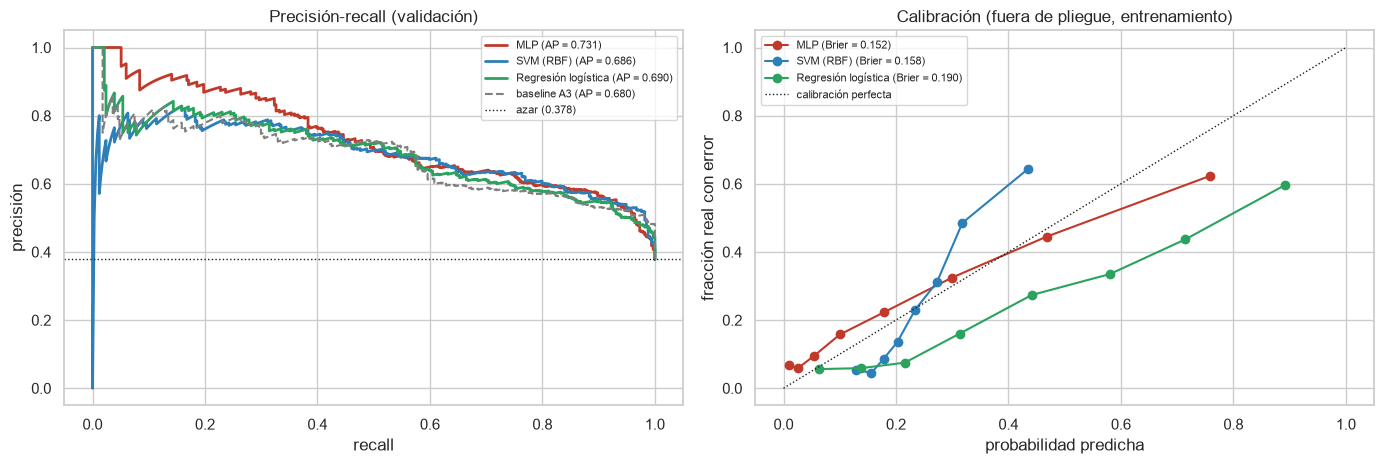

,MLP,SVM (RBF),Regresión logística
MLP,1.000,0.896,0.908
SVM (RBF),0.896,1.000,0.863
Regresión logística,0.908,0.863,1.000


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
colors = dict(zip(TOP3, [RED, BLUE, GREEN]))
for n in TOP3:
    prec, rec, _ = precision_recall_curve(y_va, final_res[n]["p_va"])
    axes[0].plot(rec, prec, color=colors[n], lw=2, label=f"{n} (AP = {final_res[n]['val']['AUC-PR']:.3f})")
    fr, mp = calibration_curve(y_tr, final_res[n]["p_oof"], n_bins=8, strategy="quantile")
    axes[1].plot(mp, fr, "o-", color=colors[n], label=f"{n} (Brier = {final_res[n]['cv']['Brier']:.3f})")
prec, rec, _ = precision_recall_curve(y_va, res_a3["p_va"])
axes[0].plot(rec, prec, color=GRAY, ls="--", lw=1.5, label=f"baseline A3 (AP = {res_a3['val']['AUC-PR']:.3f})")
axes[0].axhline(PREV_VA, color="k", ls=":", lw=1, label=f"azar ({PREV_VA:.3f})")
axes[0].set_xlabel("recall"); axes[0].set_ylabel("precisión")
axes[0].set_title("Precisión-recall (validación)"); axes[0].legend(fontsize=8)
axes[1].plot([0, 1], [0, 1], "k:", lw=1, label="calibración perfecta")
axes[1].set_xlabel("probabilidad predicha"); axes[1].set_ylabel("fracción real con error")
axes[1].set_title("Calibración (fuera de pliegue, entrenamiento)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Diversidad: correlación de Spearman entre las probabilidades fuera de pliegue (útil para el stacking).
pd.DataFrame({n: final_res[n]["p_oof"] for n in TOP3}).corr("spearman")

**Interpretación**

- **Diferencia contra la varianza.** MLP y SVM están **empatados**: la SVM queda 0.003 abajo, con una desviación de la diferencia por pliegue de 0.053, y supera al MLP en 1 de 5 pliegues. Además, el 0.602 del MLP es el **máximo** de 10 semillas: su media es 0.589 (0.563–0.602), por debajo de la SVM, que es determinista. La regresión logística, en cambio, queda **consistentemente** abajo (−0.034, peor en 5 de 5 pliegues, con una desviación de la diferencia de solo 0.024): esa brecha sí es real.
- **Estabilidad.** La SVM tiene la menor variación entre pliegues (0.024, contra 0.041–0.045).
- **Interpretabilidad.** Solo la regresión logística se explica con coeficientes. La SVM y el MLP necesitan métodos agnósticos (importancia por permutación a nivel global).
- **Tiempo en CPU.** Todos entrenan en menos de un segundo y predicen 1,000 pasos en milisegundos (SVM ~0.1 s). Para un video de unos 15–40 pasos el costo es despreciable en cualquiera de los tres: este criterio no discrimina.
- **Calibración.** El MLP, que no usa pesos de clase, es el mejor calibrado en CV (Brier 0.152), seguido de la SVM con Platt (0.158). La regresión logística sobreestima las probabilidades por `class_weight="balanced"` (0.190), como en el avance 3. La curva de la SVM tiene un rango comprimido (0.1–0.45) y una pendiente más inclinada que la diagonal: subestima el riesgo de los pasos de puntaje más alto. Ordena bien, pero habría que recalibrarla antes de usarla en el semáforo.
- **`rec_duration`.** La SVM es la que menos depende de ella (−0.051 y 0.549 sin ella en CV), seguida del MLP (−0.069) y de la regresión logística (−0.087).
- **Diversidad.** Las probabilidades fuera de pliegue de los tres están muy correlacionadas (Spearman 0.86–0.91), con el par SVM–regresión logística como el menos parecido. Esto anticipa que el *stacking* del avance 5 tendrá poco margen si solo combina estos tres.

### 6.2 Verificación: todo el preprocesamiento dentro de un `Pipeline`

Se repite la validación cruzada de los tres mejores con el preprocesamiento del avance 2 **dentro** de un `Pipeline` de scikit-learn, reajustado en cada pliegue a partir de la tabla cruda de pasos. Se construye con las mismas funciones y decisiones de `sopvid.features` que usa `build_features` (`make_preprocessor` con `FINAL_TRANSFORMS`, `FINAL_SCALER`, `FINAL_HIGH_CARD` y la selección del avance 2 más `duration`). Si las cifras coinciden con las de 6.1, ajustar la matriz con todo entrenamiento (protocolo del avance 3) no infló los resultados.

In [16]:
steps_tr = fe.prepare_steps(parts["train"], raw.video_info, graphs)
assert steps_tr.index.equals(X_tr.index)


def full_pipeline(model):
    prep = fe.make_preprocessor(numeric=fe.NUMERIC, transforms=fe.FINAL_TRANSFORMS, scaler=fe.FINAL_SCALER,
                                high_card=fe.FINAL_HIGH_CARD, select=[*fe.FINAL_SELECTED, "duration"],
                                select_prefixes=fe.FINAL_SELECTED_PREFIXES)
    return Pipeline([("prep", prep), ("clf", clone(model))])


check_pipe = []
for n in TOP3:
    f = cross_val_score(full_pipeline(final_models[n]), steps_tr, y_tr, groups=steps_tr["recording_id"],
                        cv=CV, scoring="average_precision", n_jobs=N_JOBS)
    check_pipe.append({"modelo": n, "AUC-PR CV (matriz del avance 3)": final_res[n]["folds"].mean(),
                       "AUC-PR CV (Pipeline completo por pliegue)": f.mean(), "desv.": f.std(),
                       "diferencia": f.mean() - final_res[n]["folds"].mean()})
pd.DataFrame(check_pipe).set_index("modelo")

,AUC-PR CV (matriz del avance 3),AUC-PR CV (Pipeline completo por pliegue),desv.,diferencia
modelo,,,,
MLP,0.602,0.601,0.038,-0.002
SVM (RBF),0.599,0.604,0.026,0.005
Regresión logística,0.568,0.571,0.044,0.003


**Interpretación** Con todo el preprocesamiento reajustado en cada pliegue, el AUC-PR CV cambia como mucho 0.005, muy por debajo de la desviación entre pliegues (0.026–0.044), y el orden de los tres no cambia. Ajustar las transformaciones no supervisadas con todo entrenamiento (protocolo del avance 3) no infla los resultados.

### 6.3 Elección del modelo individual final

Validación **no** se usó para esta decisión; se reporta en la celda siguiente.

| Criterio | MLP | SVM (RBF) | Regresión logística |
|---|---|---|---|
| AUC-PR CV | 0.602 con `SEED`; **0.589 de media en 10 semillas** | **0.599, determinista** | 0.568 |
| Diferencia frente al mejor | (referencia) | Empate: −0.003, desv. por pliegue 0.053 | −0.034 en 5 de 5 pliegues: diferencia real |
| Variación entre pliegues | 0.041 | **0.024** | 0.045 |
| Interpretabilidad | baja | baja | **alta** |
| Tiempo en CPU | despreciable | despreciable (~1 s de entrenamiento) | despreciable |
| Calibración (Brier CV) | **0.152** | 0.158 | 0.190 |
| AUC-PR CV sin `rec_duration` | 0.533 (−0.069) | **0.549 (−0.051)** | 0.481 (−0.087) |

**Modelo individual final: SVM con núcleo RBF** (C ≈ 33, gamma ≈ 0.016, `class_weight="balanced"`, probabilidades con Platt).

1. **Empata en el mejor AUC-PR CV y su resultado no depende de la semilla.** La ventaja aparente del MLP es suerte de la semilla: en promedio queda 0.010 abajo.
2. **Es el más estable entre pliegues.** Para un producto que verá líneas y operadores nuevos, la estabilidad entre grupos de grabaciones pesa más que una décima de AUC-PR.
3. **Es el que menos depende de `rec_duration`** y el mejor de los tres sin ella (0.549 en CV). Es el criterio más cercano a la planta, donde la duración del video depende de cómo se grabe y no de si hubo errores.
4. **Su calibración es comparable a la del MLP** y mucho mejor que la de la regresión logística. Aun así, deberá recalibrarse antes del semáforo.
5. **El costo en CPU no es una restricción:** menos de un segundo por video, en local y sin GPU.

**En contra:** es poco interpretable. Se mitiga con importancia por permutación y manteniendo la regresión logística en el *stacking* como referencia explicable. Si el patrocinador exigiera explicaciones por coeficiente, la regresión logística es la alternativa, a un costo de ~0.03 de AUC-PR. **Punto a revisar por el equipo:** en validación, el MLP rinde más (0.731 contra 0.686). No se usó para decidir, pero conviene discutirlo antes del avance 5.

In [ ]:
FINAL = "SVM (RBF)"  # decisión argumentada en la celda anterior
assert FINAL in TOP3

In [18]:
rf, rfb = final_res[FINAL], final_res_b[FINAL]
THR = rf["thr"]  # umbral elegido con probabilidades fuera de pliegue de entrenamiento
fit_tab = pd.DataFrame({
    "CV agrupada (fuera de pliegue)": rf["cv"],
    "validación (no vista)": rf["val"],
    "validación, sin rec_duration": rfb["val"],
}).T
fit_tab["prevalencia"] = [PREV_TR, PREV_VA, PREV_VA]
fit_tab["lift AUC-PR"] = fit_tab["AUC-PR"] / fit_tab["prevalencia"]
fit_tab["M1 (lift ≥ 1.5)"] = np.where(fit_tab["lift AUC-PR"] >= MIN_LIFT, "sí", "no")
fit_tab["M3 (recall ≥ 70 %, precisión ≥ 1.4 × prev.)"] = np.where(
    (fit_tab["Recall"] >= MIN_RECALL) & (fit_tab["Precisión"] >= MIN_PREC_LIFT * fit_tab["prevalencia"]), "sí", "no")
print(f"Modelo final: {FINAL} | umbral de operación (máx. F2 fuera de pliegue): {THR:.3f} | "
      f"sin rec_duration: {rfb['thr']:.3f}")
fit_tab

Modelo final: SVM (RBF) | umbral de operación (máx. F2 fuera de pliegue): 0.207 | sin rec_duration: 0.195


,AUC-PR,ROC-AUC,F2,Recall,Precisión,% marcados,Brier,prevalencia,lift AUC-PR,M1 (lift ≥ 1.5),"M3 (recall ≥ 70 %, precisión ≥ 1.4 × prev.)"
CV agrupada (fuera de pliegue),0.563,0.800,0.702,0.867,0.398,54.268,0.158,0.249,2.258,sí,sí
validación (no vista),0.686,0.819,0.750,0.799,0.601,50.226,0.213,0.378,1.817,sí,sí
"validación, sin rec_duration",0.646,0.764,0.744,0.844,0.504,63.235,0.221,0.378,1.709,sí,no


**Interpretación**

- **Desempeño mínimo.** La SVM cumple M1 y M3 en CV y en validación. Con el umbral elegido en entrenamiento (0.21), en validación encuentra **80 % de los pasos con error con una precisión de 60 %, marcando la mitad de los pasos** (lift 1.82). El baseline del avance 3 encontraba 87 % con 54 % de precisión marcando 61 % de los pasos. La SVM marca menos y acierta más, pero deja pasar más errores.
- **El recall más bajo es efecto del umbral, no del orden.** Las curvas precisión-recall de 6.1 se encimen desde un recall de ~0.4. Como en planta pesa más no dejar pasar un error, el umbral de operación del producto deberá elegirse en el avance 5 con probabilidades recalibradas, y probablemente quedará más bajo que 0.21.
- **De CV a validación** el lift baja de 2.26 a 1.82, una caída parecida a la del baseline (2.06 → 1.80): no hay señales de un sobreajuste mayor que el del modelo lineal.
- **Sin `rec_duration`** la SVM conserva M1 (lift 1.71) pero no M3 en validación: su precisión (0.504) queda por debajo del mínimo (0.529). La versión transferible todavía no alcanza el criterio de negocio completo.

### 6.4 Los tres mejores individuales para el *stacking* del avance 5

El avance 5 combinará estos tres modelos con un `StackingClassifier`. Se fijan aquí, con sus hiperparámetros, para que el avance 5 no los vuelva a elegir.

In [19]:
def short_params(est):
    # Hiperparámetros distintos de los valores por defecto (repr compacta de scikit-learn, 4 cifras).
    text = re.sub(r"\s+", " ", repr(est))
    return re.sub(r"np\.float64\(([-\d.e]+)\)", lambda m: f"{float(m.group(1)):.4g}", text)


stack_tab = pd.DataFrame([{
    "posición": i + 1, "modelo": n, "ajustado en 5.2": "sí" if n in tuned else "no",
    "configuración": short_params(final_models[n]),
    "AUC-PR CV": final_res[n]["folds"].mean(), "desv. CV": final_res[n]["folds"].std(),
    "AUC-PR val": final_res[n]["val"]["AUC-PR"], "AUC-PR CV sin rec_duration": final_res_b[n]["folds"].mean(),
} for i, n in enumerate(TOP3)]).set_index("posición")
with pd.option_context("display.max_colwidth", None):
    display(stack_tab)

,modelo,ajustado en 5.2,configuración,AUC-PR CV,desv. CV,AUC-PR val,AUC-PR CV sin rec_duration
posición,,,,,,,
1,MLP,sí,"MLPClassifier(alpha=0.2582, early_stopping=True, hidden_layer_sizes=(32, 16), learning_rate_init=0.01001, max_iter=1000, random_state=51)",0.602,0.041,0.731,0.533
2,SVM (RBF),sí,"CalibratedClassifierCV(cv=3, ensemble=False, estimator=SVC(C=32.83, class_weight='balanced', gamma=0.01581, random_state=51))",0.599,0.024,0.686,0.549
3,Regresión logística,no,"LogisticRegression(class_weight='balanced', max_iter=5000)",0.568,0.045,0.690,0.481


## 7. Conclusiones



**Respuestas a las preguntas guía**

1. **Algoritmos candidatos.** Se compararon ocho modelos individuales de seis familias (lineal, árbol, instancias, núcleo, generativos y red neuronal), con el mismo protocolo del avance 3. Los de frontera suave (SVM RBF, MLP regularizado, regresión logística y LDA) quedan arriba y juntos. El árbol y Naive Bayes no superan a la mejor regla simple en CV.
2. **Mejor desempeño.** Tras el ajuste, el MLP (0.602) y la SVM (0.599) superan en CV a la regresión logística con `duration` (0.568) y al baseline del avance 3 (0.551). En validación quedan entre 0.686 y 0.731, contra 0.680 del baseline. La ganancia es modesta y, frente a la regresión logística, consistente entre pliegues: el subajuste del avance 3 se reduce, pero ninguna curva de CV pasa de ~0.60.
3. **`rec_duration`.** Quitarla cuesta entre 0.05 y 0.09 de AUC-PR en todos los modelos que la aprovechan. La SVM ajustada es la que menos depende de ella (0.549 en CV, 0.646 en validación sin ella).
4. **Hiperparámetros.** En la SVM manda `gamma` (el alcance del núcleo), seguido del núcleo y de C. En el MLP manda la tasa de aprendizaje, por su interacción con `early_stopping`. La mejor configuración del MLP usa una regularización L2 fuerte (`alpha` ≈ 0.26). El ajuste fino mejora el AUC-PR CV en +0.010 (SVM) y +0.034 (MLP), pero validación no lo confirma y parte de la mejora del MLP es suerte de la semilla.
5. **Sub/sobreajuste.** Con más capacidad aparece la brecha que el baseline no tenía: ~0.10 (SVM) y ~0.14 (MLP) entre entrenamiento y CV en las mejores configuraciones. Las curvas de validación muestran los dos extremos (subajuste con gamma o tasa de aprendizaje bajos, sobreajuste con gamma alto), y los valores elegidos quedan en el punto de equilibrio.
6. **Modelo individual final.** SVM con núcleo RBF (C ≈ 33, gamma ≈ 0.016, Platt): empata en el mejor AUC-PR CV, es determinista, es la más estable entre pliegues y la que menos depende de `rec_duration`, con un costo en CPU despreciable. Su punto débil es la interpretabilidad.
7. **Para el *stacking* del avance 5:** MLP, SVM (RBF) y regresión logística (tabla 6.4).

**Riesgos y siguientes pasos**

- **Dependencia de la grabación.** Sigue siendo la señal principal. La variante sin `rec_duration` cumple M1 pero no M3 en validación. El avance 5 debe reportar ambas variantes.
- **Poca diversidad para el *stacking*.** Los tres mejores están muy correlacionados (Spearman 0.86–0.91). Los ensambles de árboles del avance 5 (bosques, LightGBM) pueden aportar un tipo de error distinto.
- **Calibración y umbral.** La SVM comprime sus probabilidades y el MLP depende de la semilla. Antes del semáforo, el modelo final debe recalibrarse con validación cruzada agrupada y su umbral elegirse con el criterio de negocio (recall primero).
- **Semillas.** Si el MLP entra al *stacking*, conviene promediar varias semillas o reportar su variación.
- **Prueba** sigue sin tocarse: se usará una sola vez, con el modelo final del avance 5.

### 7.1 Tabla de referencia para el avance 5

In [20]:
def ref_row(name, r, cols_note=""):
    return {"modelo": name + cols_note, "AUC-PR CV": r["folds"].mean(), "AUC-PR val": r["val"]["AUC-PR"],
            "ROC-AUC val": r["val"]["ROC-AUC"], "F2 val": r["val"]["F2"], "Recall val": r["val"]["Recall"],
            "Precisión val": r["val"]["Precisión"], "entrenamiento (ms)": r["fit_ms"]}


summary = pd.DataFrame([
    {"modelo": "Azar (prevalencia)", "AUC-PR CV": PREV_TR, "AUC-PR val": PREV_VA},
    {"modelo": BEST_RULE, "AUC-PR CV": ref.loc[BEST_RULE, "AUC-PR train"], "AUC-PR val": ref.loc[BEST_RULE, "AUC-PR val"]},
    ref_row("Baseline del avance 3: regresión logística", res_a3, " (35 col.)"),
    *[ref_row(f"{n}{' — FINAL' if n == FINAL else ''}", final_res[n], " (36 col.)") for n in TOP3],
    ref_row(f"{FINAL} sin rec_duration", final_res_b[FINAL], " (35 col.)"),
]).set_index("modelo")
print(f"Tiempo total de ejecución: {(time.perf_counter() - T_START) / 60:.1f} min")
summary

Tiempo total de ejecución: 1.9 min


,AUC-PR CV,AUC-PR val,ROC-AUC val,F2 val,Recall val,Precisión val,entrenamiento (ms)
modelo,,,,,,,
Azar (prevalencia),0.249,0.378,NaN,NaN,NaN,NaN,NaN
Regla de grabación: video más corto,0.401,0.503,NaN,NaN,NaN,NaN,NaN
Baseline del avance 3: regresión logística (35 col.),0.551,0.680,0.802,0.777,0.871,0.542,19.031
MLP (36 col.),0.602,0.731,0.822,0.818,0.961,0.512,141.398
SVM (RBF) — FINAL (36 col.),0.599,0.686,0.819,0.750,0.799,0.601,828.237
Regresión logística (36 col.),0.568,0.690,0.807,0.787,0.883,0.547,20.632
SVM (RBF) sin rec_duration (35 col.),0.549,0.646,0.764,0.744,0.844,0.504,933.041


## Referencias

- Bergstra, J., y Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research, 13*, 281–305.
- Géron, A. (2022). *Hands-on machine learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
- Niculescu-Mizil, A., y Caruana, R. (2005). Predicting good probabilities with supervised learning. *Proceedings of the 22nd International Conference on Machine Learning*, 625–632.
- Peddi, R., et al. (2024). CaptainCook4D: A dataset for understanding errors in procedural activities. *NeurIPS 2024 Datasets and Benchmarks Track.* https://arxiv.org/abs/2312.14556
- Platt, J. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. *Advances in Large Margin Classifiers*, 61–74.
- Saito, T., y Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLOS ONE, 10*(3), e0118432.
- Studer, S., Bui, T. B., Drescher, C., Hanuschkin, A., Winkler, L., Peters, S., y Müller, K.-R. (2021). Towards CRISP-ML(Q): A machine learning process model with quality assurance methodology. *Machine Learning and Knowledge Extraction, 3*(2), 392–413.